# A Transformer-Based Approach for Raw EEG Classification

This notebook focuses on the F_CTrans architecture for raw EEG classification, based on the paper "A Transformer-Based Approach Combining Deep Learning Network and Spatial-Temporal Information for Raw EEG Classification" by Jin Xie et al. (2022). In addition to reproducing the core architecture, this notebook includes independent experimentation through hyperparameter grid search and the evaluation of an alternative custom-modified model variant.
>⚠️ **Identified Issue:** 
A critical configuration error was discovered in the band-pass filter: the lower cutoff frequency was mistakenly set to **8 Hz** instead of **0.5 Hz**. This limited the model's learning capacity.



## 1. Setup and Imports

In this section, I set up the working environment, import all necessary libraries and set a fixed seed (42) to ensure reproducibility across all experiments.


In [1]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

In [ ]:
import numpy as np
from pathlib import Path
import re
import sys
import random

src_path = Path('../src/eeg_bci_transformer_pipeline').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from datapreprocessing import EEGpreprocessing, EEGDataset
from train import  EEGTrainer
from models import F_CTrans , F_CTrans_modified


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

## 2. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [5]:
CURRENT_DIR = Path.cwd()

DATASET_PATH = (CURRENT_DIR.parent / "data" / "MotorImagery(04,08,012)") 

print(f"Dataset path used: {DATASET_PATH}")

edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")


Dataset path used: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)
File EDF for Train/Validation: 294
File EDF for TEST: 33


In this section, I apply preprocessing pipeline to the raw EDF files:
* **Bandpass Filtering & Resampling**: Filtering between 8 Hz and 30.0 Hz with resampling to 160.0 Hz.
* **Epoching**: Extracting 4-second windows (`0.0` to `4.0` seconds).
* **PSD Analysis**: Computing the Power Spectral Density via Welch's method for quality control/feature recording.
* **Label Mapping**: Extracting events and mapping classes to binary labels (`Left = 0`, `Right = 1`).

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import mne

X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    print(f"Subject Processing {subj_id} - File: {file_path}")

    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
    except Exception as e:
        print(f"❌ ERROR: Unable to read Subject file {subj_id}!")
        print(f"   Path: {file_path}")
        print(f"   Detail: {e}")
        continue

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    if len(epochs_mne) == 0:
        print(f"⚠️ Warning: No epoch found for Subject {subj_id}. Jump.")
        continue
    
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch', verbose=False)
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,
        'psd_data': psd_values,
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2))
    })

    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_trials, 64, 480)

    # Label extraction and mapping (Left = 0, Right = 1)
    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    
    labels = np.zeros(len(y), dtype=np.int64)
    if 'Left' in event_id and event_id['Left'] in y:
        labels[y == event_id['Left']] = 0
    if 'Right' in event_id and event_id['Right'] in y:
        labels[y == event_id['Right']] = 1

   
    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

print(" Extraction cycle completed successfully!")
print(f"Subjects processed correctly: {len(X_raw_list)}")

Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
N

/tmp/ipykernel_173928/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
1 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
10 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 10 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata


/tmp/ipykernel_173928/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 36 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S036/S036R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Proce

/tmp/ipykernel_173928/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


... (3 outputs left out)

/tmp/ipykernel_173928/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
/tmp/ipykernel_173928/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 100 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S100/S100R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R04.edf


/tmp/ipykernel_173928/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 e

In [8]:

X_test_raw_list = []
y_test_list = []
test_subject_ids_list = []


for i, rec in enumerate(test_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    print(f"Processing Test Subject {subj_id} - File: {file_path.name}")

    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1')
    except Exception as e:
        print(f"❌ ERROR: Unable to read Test Subject file {subj_id}!")
        print(f"   Path: {file_path}")
        print(f"   Detail: {e}")
        continue

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    if len(epochs_mne) == 0:
        print(f"⚠️ Warning: No epoch found for Test Subject {subj_id}. Jump.")
        continue

    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_trials, 64, 480)

    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    
    labels = np.zeros(len(y), dtype=np.int64)
    if 'Left' in event_id and event_id['Left'] in y:
        labels[y == event_id['Left']] = 0
    if 'Right' in event_id and event_id['Right'] in y:
        labels[y == event_id['Right']] = 1

    X_test_raw_list.append(X_raw)
    y_test_list.append(labels)
    test_subject_ids_list.extend([subj_id] * len(X_raw))




print(" Extraction cycle completed successfully!")
print(f"Subjects processed correctly: {len(X_test_raw_list)}")

Processing Test Subject 5 - File: S005R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Processing Test Subject 5 - File: S005R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Processing Test Subject 5 - File: S005R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Processing Test Subject 11 - File: S011R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not

Convert to PyTorch tensors

In [9]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Shape X_train_val : {X_training_validation_raw.shape}")
print(f"Shape y_train_val: {y_training_validation.shape}")
print("Label distribution:", np.unique(y_training_validation, return_counts=True))


X_test_raw = np.concatenate(X_test_raw_list, axis=0)
y_test = np.concatenate(y_test_list, axis=0)
test_subject_ids = np.array(test_subject_ids_list)


print(f"Shape X_test : {X_test_raw.shape}")
print(f"Shape y_test: {y_test.shape}")
print("Label distribution:", np.unique(y_test, return_counts=True))

Shape X_train_val : (4370, 64, 641)
Shape y_train_val: (4370,)
Label distribution: (array([0, 1]), array([2205, 2165]))
Shape X_test : (495, 64, 641)
Shape y_test: (495,)
Label distribution: (array([0, 1]), array([249, 246]))


## 3. Model Exploration

In this section, I perform a subject-wise 5-fold cross-validation using `GroupKFold` to prevent data leakage. 
I systematically evaluate different learning rate schedulers (`MultiStepLR` vs `ReduceLROnPlateau`) and network modifications.

### f_CTrans with MultiStepLR 

This section implements the F_CTrans architecture introduced by Jin Xie et al. (2022). I strictly follow the guidelines from Section “C. Training Setup” and Table I, adopting their identical configuration parameters alongside the `MultiStepLR` learning rate scheduler.


 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.81804, train_acc=48.58%, val_loss=0.69992, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.70078, train_acc=49.67%, val_loss=0.69339, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69948, train_acc=50.04%, val_loss=0.69707, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69609, train_acc=49.84%, val_loss=0.69668, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69561, train_acc=50.93%, val_loss=0.70782, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.70145, train_acc=48.87%, val_loss=0.69325, val_acc=49.94% | L

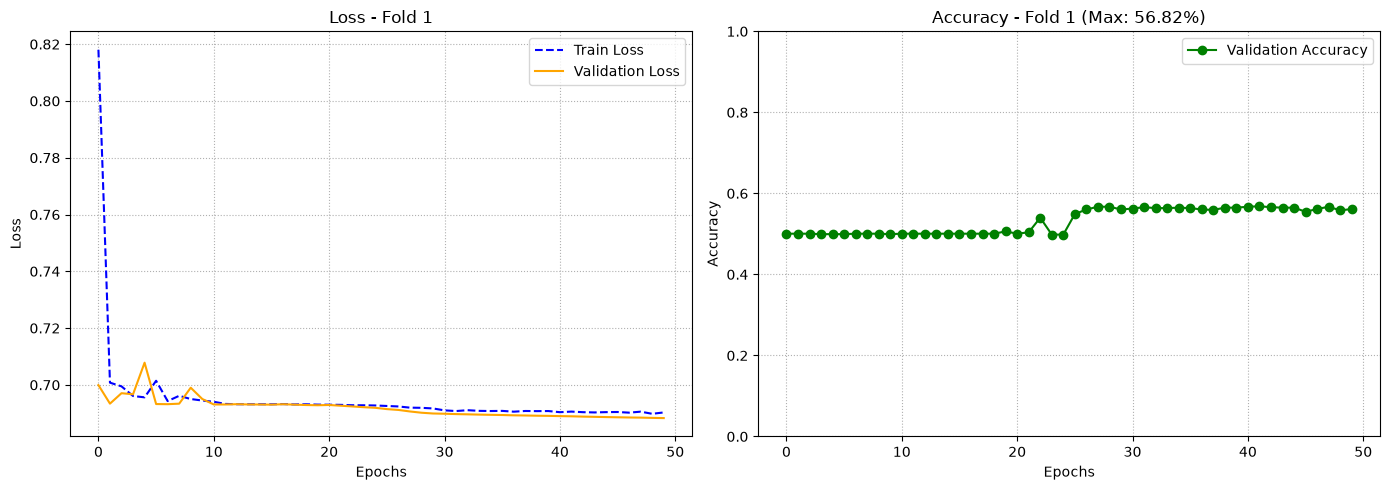


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 56.82% (± 0.00%)


In [ ]:


from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import MultiStepLR


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### f_CTrans with ReduceLROnPlateau

This section implements the F_CTrans architecture while incorporating the `ReduceLROnPlateau` learning rate scheduler.
Motivated by the slow convergence and performance plateaus observed in preliminary runs, this dynamic approach automatically scales down the learning rate when validation accuracy stops improving. 

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.76707, train_acc=49.01%, val_loss=0.69509, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.70038, train_acc=48.46%, val_loss=0.69319, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69765, train_acc=49.73%, val_loss=0.69588, val_acc=49.94% | LR: 0.001000
Epoch 04/50: train_loss=0.69692, train_acc=50.67%, val_loss=0.69370, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69826, train_acc=49.38%, val_loss=0.69718, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69423, train_acc=49.64%, val_loss=0.69306, val_acc=49.94% | L

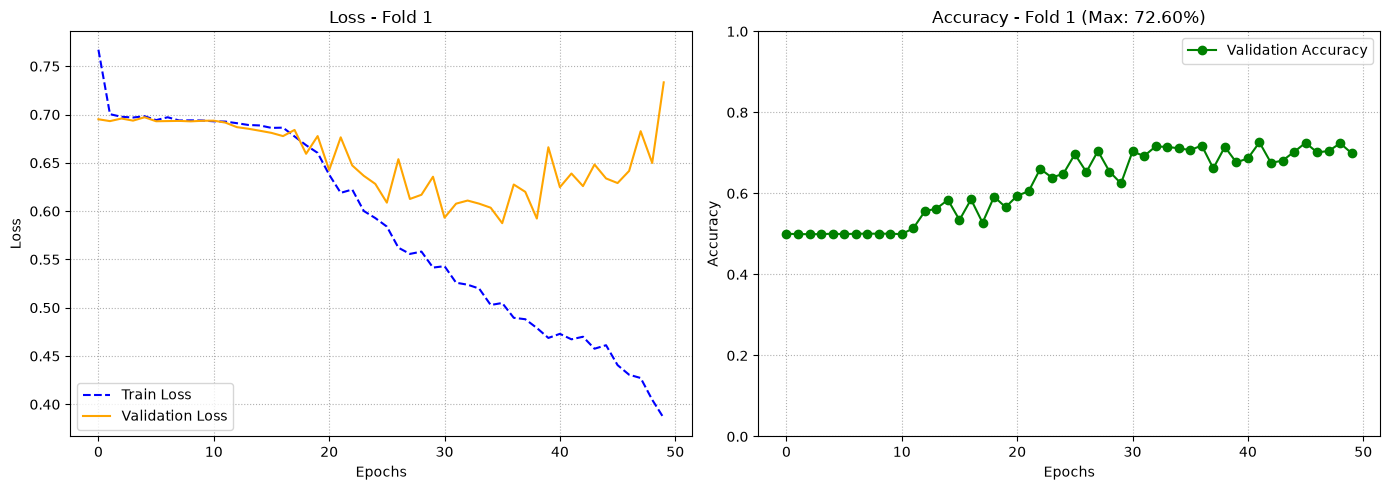


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 72.60% (± 0.00%)


In [ ]:


from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

#### Here I play with the parameters

Having noticed overfitting, I tried increasing the dropout rate to 0.5.

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.80584, train_acc=49.18%, val_loss=0.69400, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69684, train_acc=50.04%, val_loss=0.69899, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69868, train_acc=49.55%, val_loss=0.69767, val_acc=49.94% | LR: 0.001000
Epoch 04/50: train_loss=0.69720, train_acc=49.38%, val_loss=0.69421, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69542, train_acc=49.84%, val_loss=0.69355, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69639, train_acc=50.39%, val_loss=0.69941, val_acc=50.06% | L

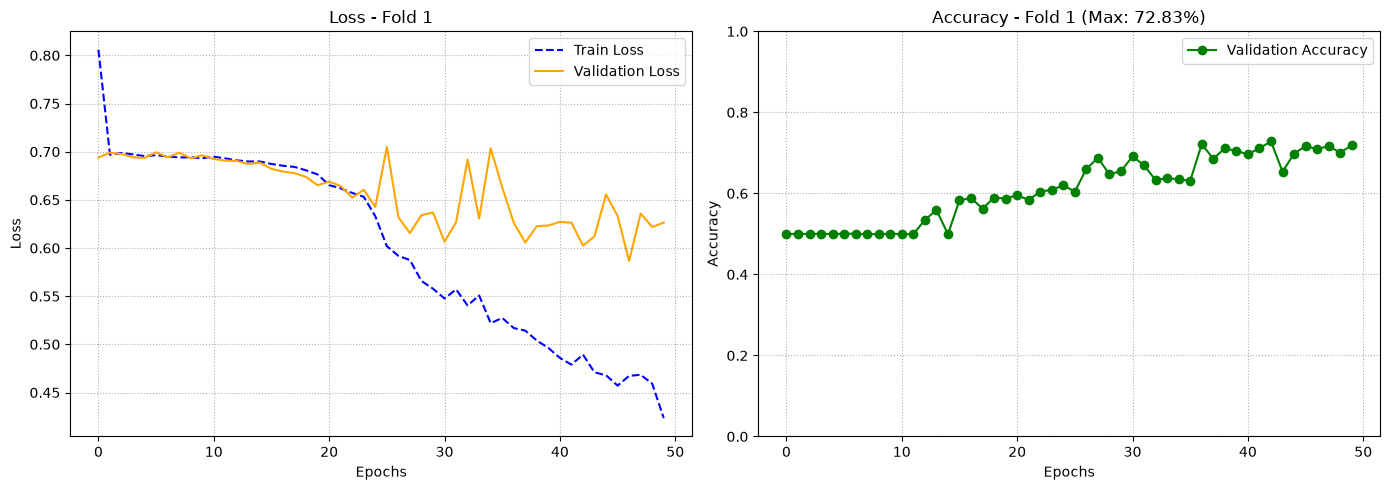


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 72.83% (± 0.00%)


In [14]:
# aumento dropout

from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.4, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

I tried to decrease the number of layers to 2

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.75167, train_acc=50.85%, val_loss=0.69433, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.70518, train_acc=50.36%, val_loss=0.69362, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69955, train_acc=51.34%, val_loss=0.69419, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69597, train_acc=49.87%, val_loss=0.69517, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69623, train_acc=49.64%, val_loss=0.69361, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69587, train_acc=50.88%, val_loss=0.69503, val_acc=49.94% | L

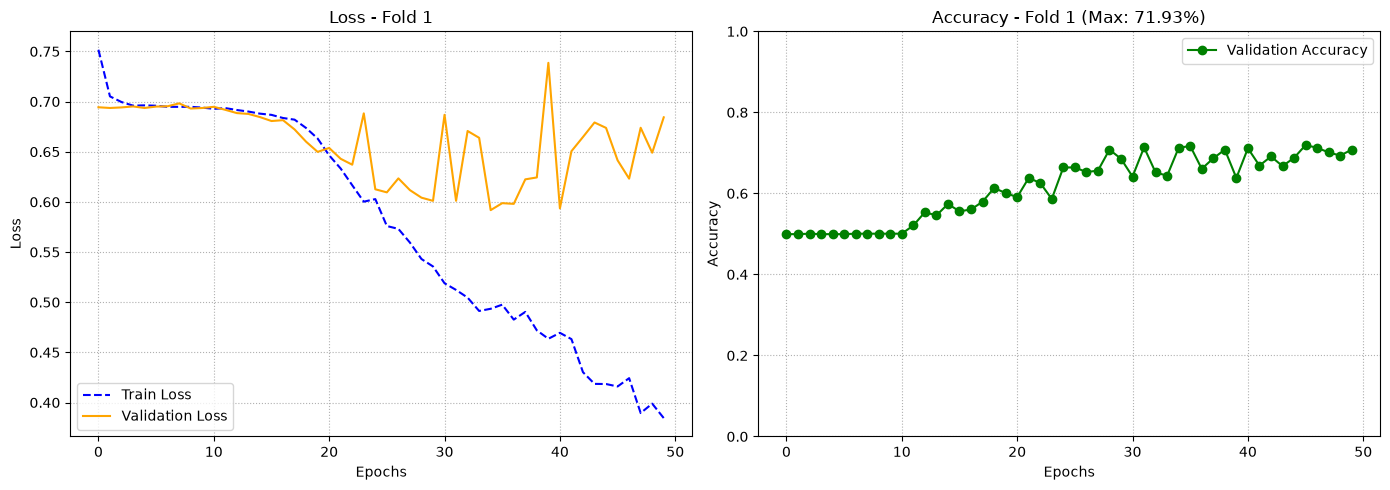


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 71.93% (± 0.00%)


In [10]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

Here, I’m keeping the number of layers at 2 while increasing the dropout again.

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.76843, train_acc=51.34%, val_loss=0.70439, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.69930, train_acc=50.22%, val_loss=0.70421, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69903, train_acc=48.75%, val_loss=0.70425, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69647, train_acc=50.73%, val_loss=0.69746, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69605, train_acc=50.67%, val_loss=0.69712, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69463, train_acc=50.73%, val_loss=0.69535, val_acc=49.94% | L

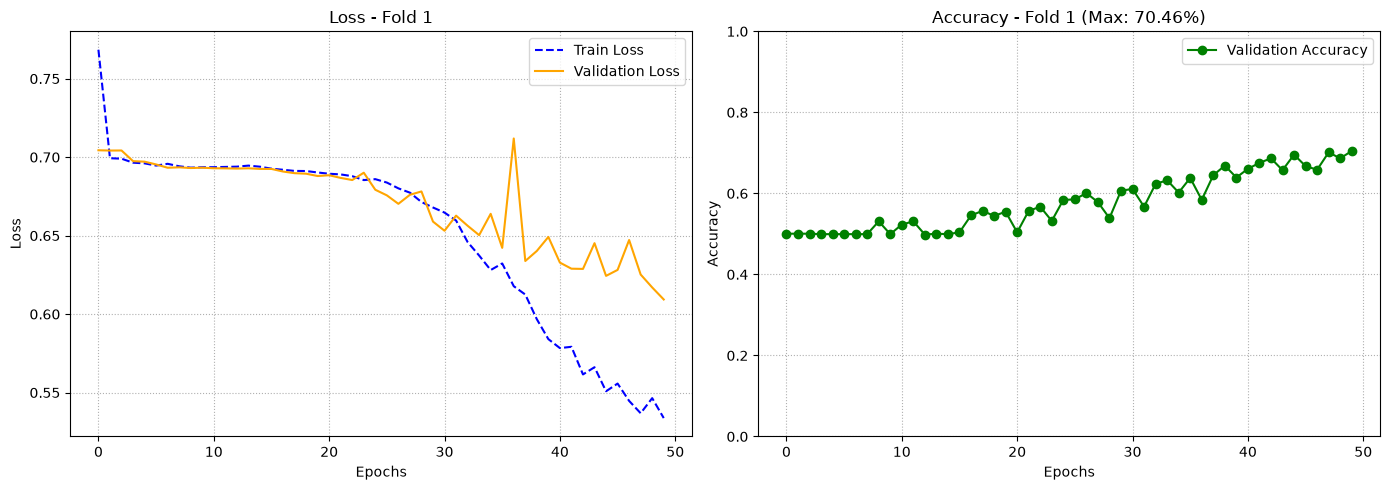


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 70.46% (± 0.00%)


In [ ]:
#aumento dropout

from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.4, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### f_CTrans_modified with MultiStepLR

In this section, I introduce F_CTrans_modified, featuring slight structural changes including:
* **Mean + Max pooling combinations**
* **Layer Normalization** 
* **enhanced MLP classifier**

while keeping the `MultiStepLR` scheduler.

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Epoch 01/50: train_loss=0.72457, train_acc=49.76%, val_loss=0.69857, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69811, train_acc=50.73%, val_loss=0.69593, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69482, train_acc=50.45%, val_loss=0.69313, val_acc=49.38% | LR: 0.001000
Epoch 04/50: train_loss=0.69470, train_acc=51.28%, val_loss=0.69379, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69482, train_acc=51.05%, val_loss=0.69413, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69507, train_acc=49.33%, val_loss=0.69358, val_acc=49.94% | LR: 0.001000
Epoch 07/50: train_loss=0.69545, train_acc=50.01%, val_loss=0.69349, val_acc=49.94% | LR: 0.001000
Epoch 08/50: train_loss=0.69385, train_acc=50.19%, val_loss=0.69389, val_acc=49.94% | LR: 0.001000
Epoch 09/50: train_loss=0.69410, train_acc=48.38%, val_loss=0.69346, val_acc=50.06% | LR: 0.001000
Epoch 10/50: train_los

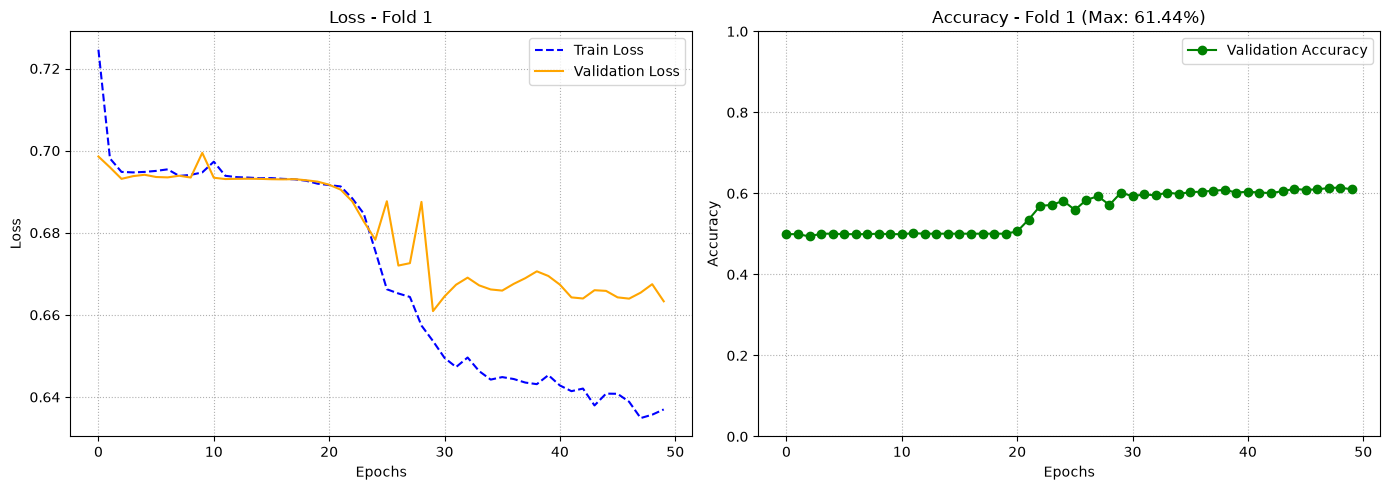


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 61.44% (± 0.00%)


In [15]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)  
    
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)


   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### f_CTrans_modified with ReduceLROnPlateau

In this section, I introduce F_CTrans_modified, featuring slight structural changes including:
* **Mean + Max pooling combinations**
* **Layer Normalization** 
* **enhanced MLP classifier**

while keeping the `ReduceLROnPlateau` scheduler..

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.70944, train_acc=48.55%, val_loss=0.69495, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69757, train_acc=49.35%, val_loss=0.70280, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69481, train_acc=49.55%, val_loss=0.70545, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69823, train_acc=48.64%, val_loss=0.69461, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69514, train_acc=49.90%, val_loss=0.69343, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69537, train_acc=50.07%, val_loss=0.69408, val_acc=50.06% | L

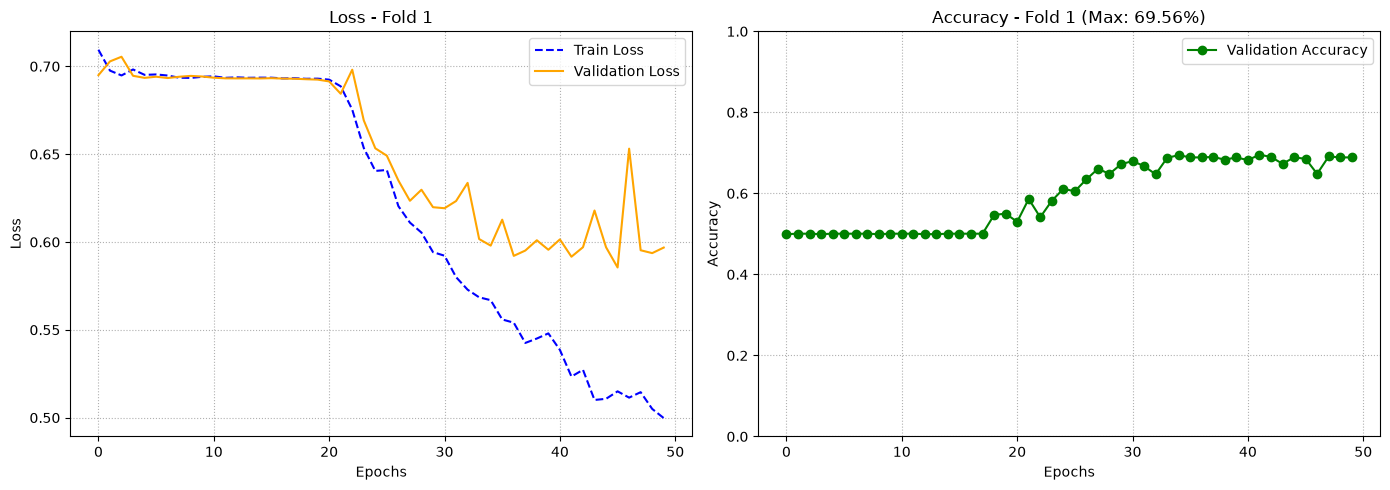


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 69.56% (± 0.00%)


In [16]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

#### Here I play with parameters

I tried to decrease the number of layers to 2

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.72517, train_acc=49.73%, val_loss=0.69417, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.69575, train_acc=51.13%, val_loss=0.69324, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69608, train_acc=50.76%, val_loss=0.69313, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69363, train_acc=52.66%, val_loss=0.69381, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69580, train_acc=49.67%, val_loss=0.69384, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69518, train_acc=49.90%, val_loss=0.69438, val_acc=50.06% | L

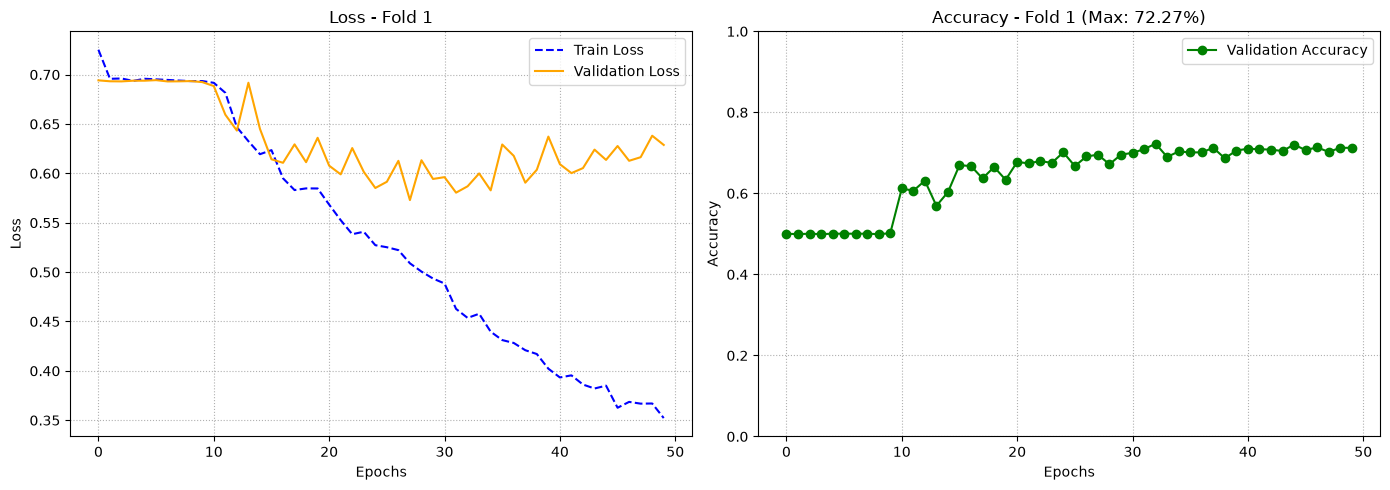


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 72.27% (± 0.00%)


In [17]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

Having noticed overfitting, I tried increasing the dropout rate to 0.4.

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.72476, train_acc=49.61%, val_loss=0.69722, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69715, train_acc=49.50%, val_loss=0.69397, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69697, train_acc=49.53%, val_loss=0.69420, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69436, train_acc=50.93%, val_loss=0.69501, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69669, train_acc=49.53%, val_loss=0.69357, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69601, train_acc=50.36%, val_loss=0.69322, val_acc=49.94% | L

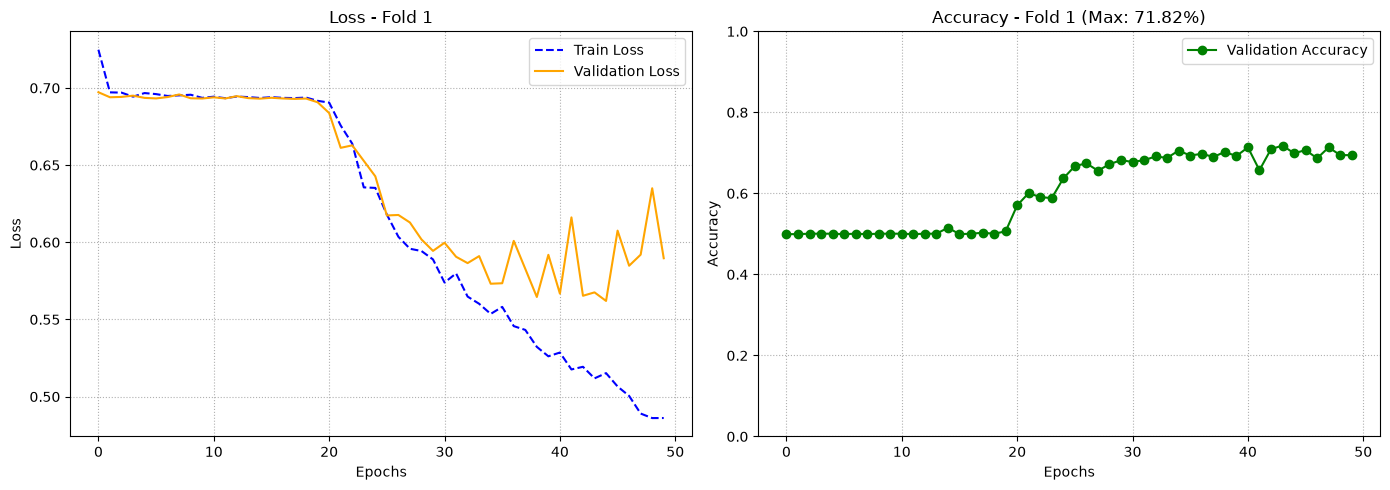


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 71.82% (± 0.00%)


In [18]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.4, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

I increased the dropout rate to 0.5, but it turned out to be too high.

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.71049, train_acc=49.18%, val_loss=0.69303, val_acc=51.07% | LR: 0.001000
Epoch 02/50: train_loss=0.69609, train_acc=48.81%, val_loss=0.69337, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69680, train_acc=47.92%, val_loss=0.69557, val_acc=49.94% | LR: 0.001000
Epoch 04/50: train_loss=0.69619, train_acc=49.93%, val_loss=0.69328, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69530, train_acc=49.70%, val_loss=0.69338, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69535, train_acc=50.36%, val_loss=0.69339, val_acc=49.94% | L

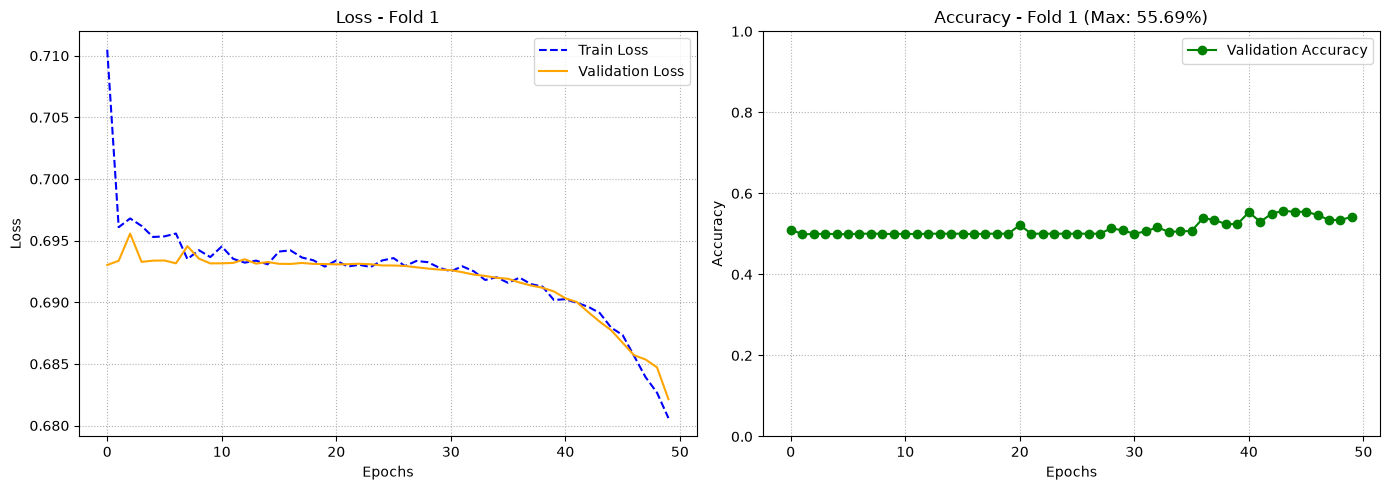


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 55.69% (± 0.00%)


In [19]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.5, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

I tried with dropout to 0.45

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)


/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/venv/lib/python3.12/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv2d(


Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.70638, train_acc=50.47%, val_loss=0.69940, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.69930, train_acc=49.10%, val_loss=0.69321, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69407, train_acc=51.45%, val_loss=0.69422, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69534, train_acc=50.56%, val_loss=0.69329, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69581, train_acc=50.16%, val_loss=0.69373, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69520, train_acc=48.72%, val_loss=0.69319, val_acc=49.94% | LR: 0.001000
Epoch 07/50: train_loss=0.69429, train_acc=49.64%, val_loss=0.69311, val_acc=50.85% | LR: 0.001000
Epoch 08/50: train_loss=0.69503, train_acc=50.10%, val_loss=0.69534, val_acc=49.94% | LR: 0.001000
Epoch 09/50: train_loss=0.69442, train_acc=50.96%, val_loss=0.69405, val_acc=49.94% | LR: 0.

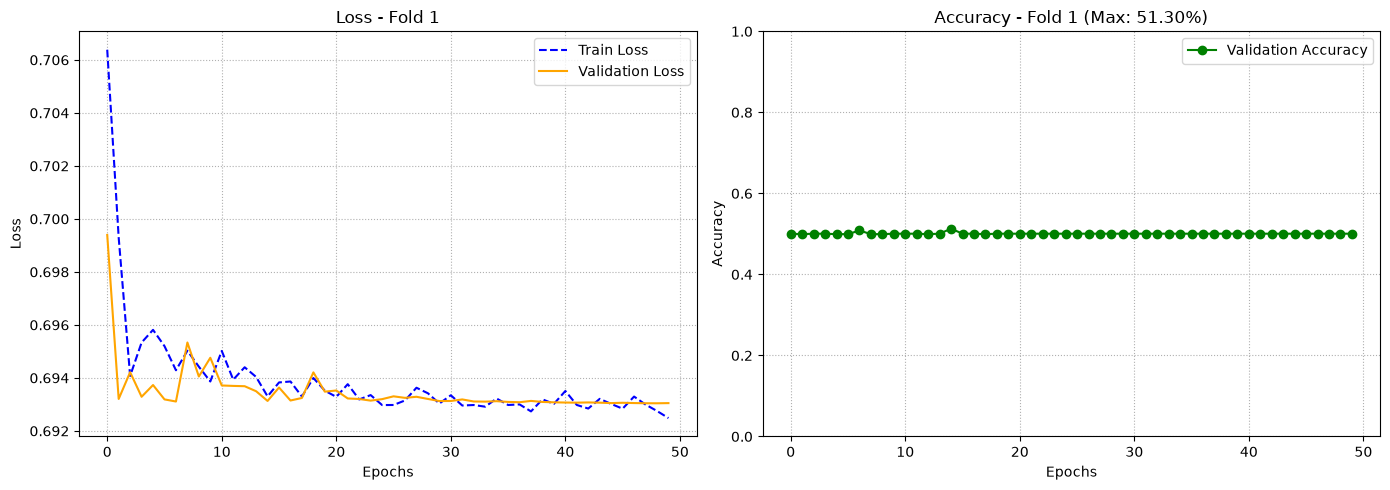


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 51.30% (± 0.00%)


In [ ]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.45, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

fold 4 fa schifo ...
 rivaluto la mia scelta ... 
 faccio di nuovo grid search

## 4. Hyperparameter Tuning (Grid Search)

Based on the previous experiments, I selected `F_CTrans_modified` (with 2 layers, `ReduceLROnPlateau`, and a dropout rate of 0.4) as the base model and performed a grid search to fine-tune its key hyperparameters.

**Evaluated parameter grid:**
- **Learning Rate (`lr`):** `[1e-3, 5e-4]`
- **Weight Decay (`weight_decay`):** `[1e-4, 5e-4, 1e-3]`

To avoid relying on a single fold, which would be too random and unreliable, the grid search was evaluated over 2 folds (specifically, the first and the fourth folds).


Detected device: GPU NVIDIA (CUDA)
--- COMBINATION 1/6 | Params: {'lr': 0.001, 'weight_decay': 0.0001} ---

--- TRAINING SU FOLD 1/5 ---


/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/venv/lib/python3.12/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv2d(


Epoch 01/60: train_loss=0.71002, train_acc=51.62%, val_loss=0.69413, val_acc=50.06% | LR: 0.001000
Epoch 02/60: train_loss=0.69568, train_acc=50.13%, val_loss=0.69470, val_acc=49.94% | LR: 0.001000
Epoch 03/60: train_loss=0.69873, train_acc=48.32%, val_loss=0.69317, val_acc=49.49% | LR: 0.001000
Epoch 04/60: train_loss=0.69479, train_acc=50.10%, val_loss=0.69312, val_acc=50.06% | LR: 0.001000
Epoch 05/60: train_loss=0.69555, train_acc=49.44%, val_loss=0.69640, val_acc=50.06% | LR: 0.001000
Epoch 06/60: train_loss=0.69549, train_acc=50.62%, val_loss=0.69351, val_acc=49.94% | LR: 0.001000
Epoch 07/60: train_loss=0.69449, train_acc=50.10%, val_loss=0.69318, val_acc=49.94% | LR: 0.000500
Epoch 08/60: train_loss=0.69406, train_acc=48.84%, val_loss=0.69322, val_acc=50.06% | LR: 0.000500
Epoch 09/60: train_loss=0.69379, train_acc=51.19%, val_loss=0.69430, val_acc=50.06% | LR: 0.000500
Epoch 10/60: train_loss=0.69484, train_acc=49.33%, val_loss=0.69311, val_acc=51.86% | LR: 0.000500
Epoch 11/6

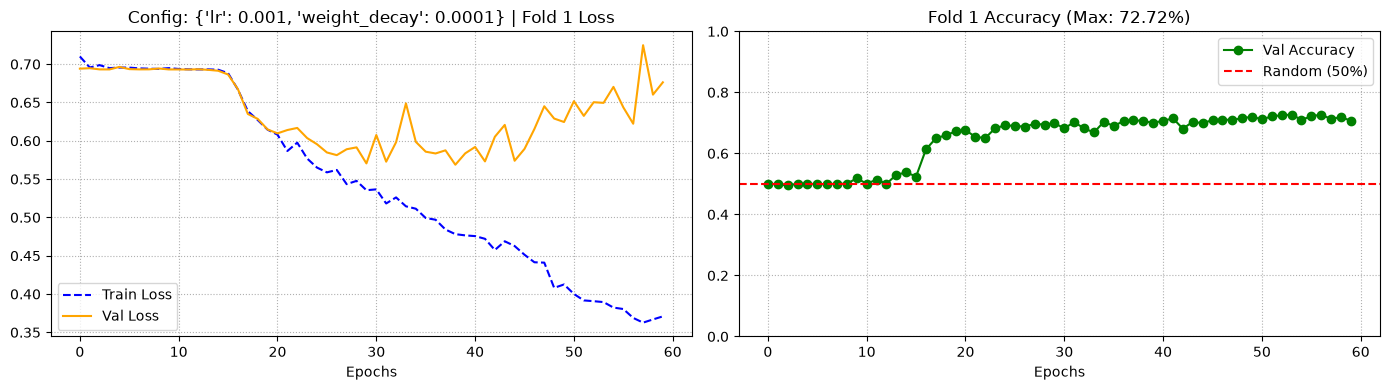


--- TRAINING SU FOLD 4/5 ---
Epoch 01/60: train_loss=0.71733, train_acc=50.36%, val_loss=0.69355, val_acc=49.49% | LR: 0.001000
Epoch 02/60: train_loss=0.69729, train_acc=48.70%, val_loss=0.69319, val_acc=50.51% | LR: 0.001000
Epoch 03/60: train_loss=0.69731, train_acc=50.70%, val_loss=0.69523, val_acc=50.51% | LR: 0.001000
Epoch 04/60: train_loss=0.69551, train_acc=49.38%, val_loss=0.70189, val_acc=50.51% | LR: 0.001000
Epoch 05/60: train_loss=0.69627, train_acc=49.58%, val_loss=0.69337, val_acc=49.49% | LR: 0.001000
Epoch 06/60: train_loss=0.69623, train_acc=50.16%, val_loss=0.69430, val_acc=50.51% | LR: 0.001000
Epoch 07/60: train_loss=0.69365, train_acc=51.36%, val_loss=0.69593, val_acc=50.51% | LR: 0.001000
Epoch 08/60: train_loss=0.69431, train_acc=50.76%, val_loss=0.69396, val_acc=49.49% | LR: 0.000500
Epoch 09/60: train_loss=0.69437, train_acc=49.38%, val_loss=0.69387, val_acc=50.51% | LR: 0.000500
Epoch 10/60: train_loss=0.69431, train_acc=48.81%, val_loss=0.69353, val_acc=50

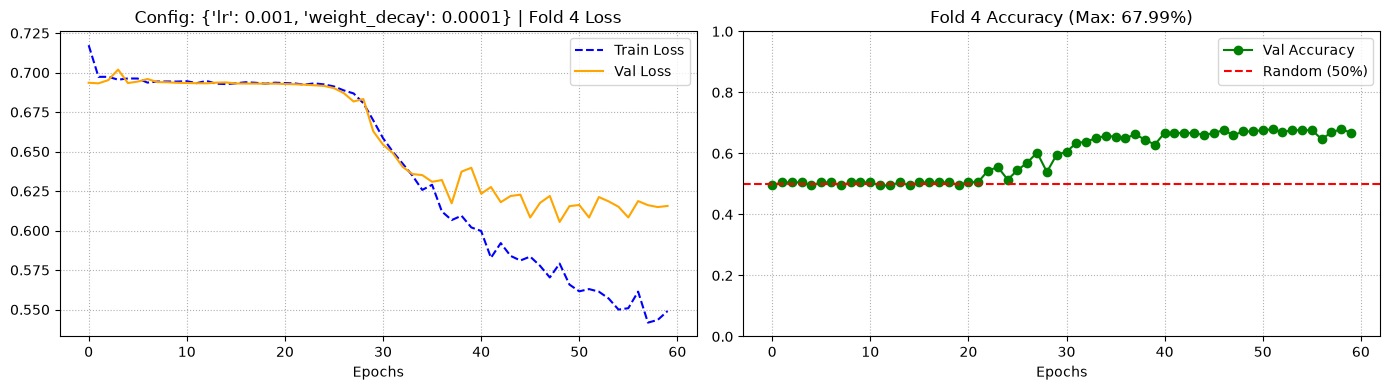

📊 Media accuracy (Fold 1 & 4) per {'lr': 0.001, 'weight_decay': 0.0001}: 70.35%
--- COMBINATION 2/6 | Params: {'lr': 0.001, 'weight_decay': 0.0005} ---

--- TRAINING SU FOLD 1/5 ---
Epoch 01/60: train_loss=0.71961, train_acc=50.67%, val_loss=0.69331, val_acc=50.06% | LR: 0.001000
Epoch 02/60: train_loss=0.69700, train_acc=50.53%, val_loss=0.69391, val_acc=50.06% | LR: 0.001000
Epoch 03/60: train_loss=0.69461, train_acc=52.02%, val_loss=0.69417, val_acc=49.94% | LR: 0.001000
Epoch 04/60: train_loss=0.69758, train_acc=49.50%, val_loss=0.69419, val_acc=49.94% | LR: 0.001000
Epoch 05/60: train_loss=0.69627, train_acc=48.72%, val_loss=0.69311, val_acc=50.39% | LR: 0.001000
Epoch 06/60: train_loss=0.69536, train_acc=49.78%, val_loss=0.69312, val_acc=50.62% | LR: 0.001000
Epoch 07/60: train_loss=0.69430, train_acc=49.84%, val_loss=0.69311, val_acc=51.63% | LR: 0.001000
Epoch 08/60: train_loss=0.69469, train_acc=50.53%, val_loss=0.69368, val_acc=50.06% | LR: 0.001000
Epoch 09/60: train_loss=0.

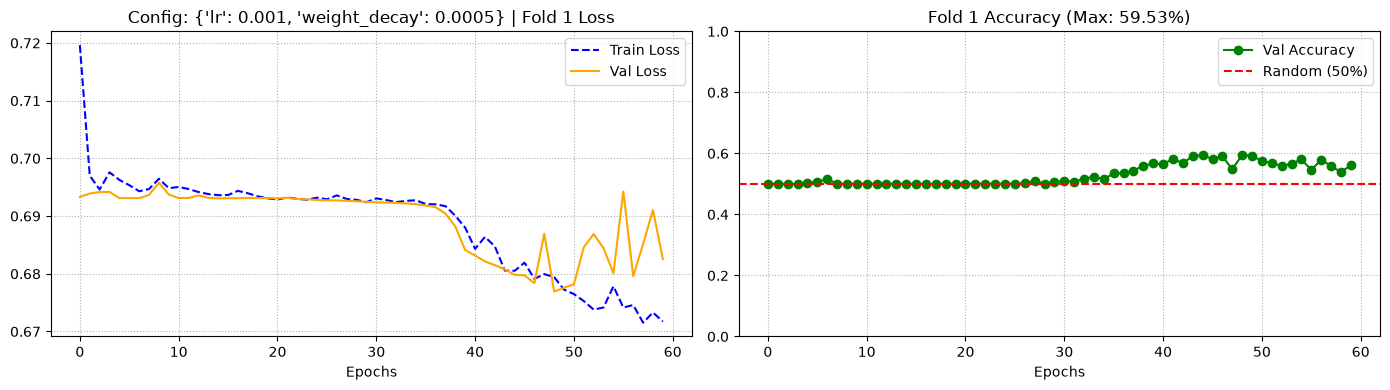


--- TRAINING SU FOLD 4/5 ---
Epoch 01/60: train_loss=0.70624, train_acc=50.70%, val_loss=0.70143, val_acc=50.51% | LR: 0.001000
Epoch 02/60: train_loss=0.69776, train_acc=49.99%, val_loss=0.69311, val_acc=52.55% | LR: 0.001000
Epoch 03/60: train_loss=0.69473, train_acc=50.42%, val_loss=0.69575, val_acc=50.51% | LR: 0.001000
Epoch 04/60: train_loss=0.69613, train_acc=49.90%, val_loss=0.69353, val_acc=49.49% | LR: 0.001000
Epoch 05/60: train_loss=0.69413, train_acc=50.36%, val_loss=0.69441, val_acc=50.51% | LR: 0.001000
Epoch 06/60: train_loss=0.69473, train_acc=50.04%, val_loss=0.69305, val_acc=50.51% | LR: 0.001000
Epoch 07/60: train_loss=0.69477, train_acc=49.64%, val_loss=0.69316, val_acc=50.51% | LR: 0.001000
Epoch 08/60: train_loss=0.69466, train_acc=49.61%, val_loss=0.69297, val_acc=50.51% | LR: 0.000500
Epoch 09/60: train_loss=0.69420, train_acc=49.18%, val_loss=0.69314, val_acc=50.51% | LR: 0.000500
Epoch 10/60: train_loss=0.69314, train_acc=50.44%, val_loss=0.69316, val_acc=49

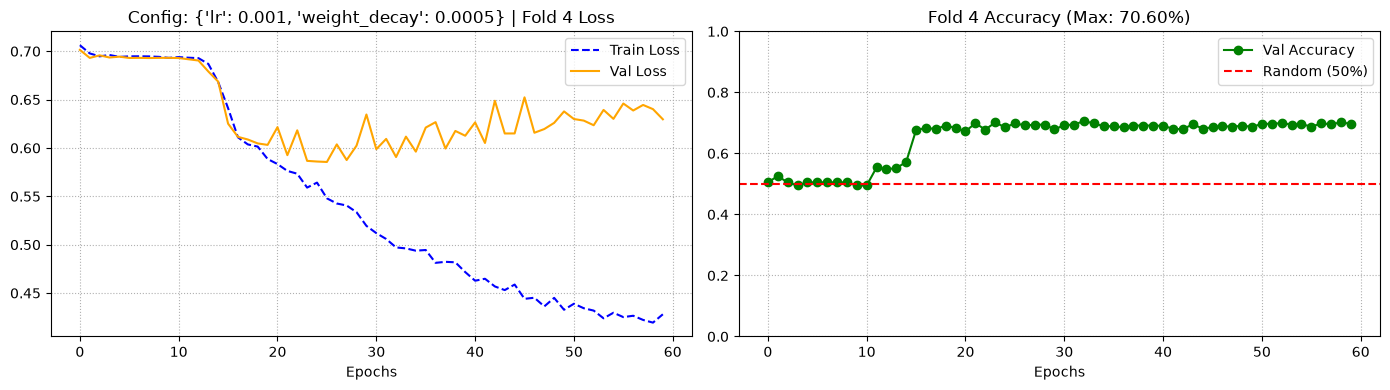

📊 Media accuracy (Fold 1 & 4) per {'lr': 0.001, 'weight_decay': 0.0005}: 65.06%
--- COMBINATION 3/6 | Params: {'lr': 0.001, 'weight_decay': 0.001} ---

--- TRAINING SU FOLD 1/5 ---
Epoch 01/60: train_loss=0.72063, train_acc=50.33%, val_loss=0.69739, val_acc=49.94% | LR: 0.001000
Epoch 02/60: train_loss=0.69696, train_acc=49.67%, val_loss=0.69632, val_acc=50.06% | LR: 0.001000
Epoch 03/60: train_loss=0.69582, train_acc=49.47%, val_loss=0.69406, val_acc=49.94% | LR: 0.001000
Epoch 04/60: train_loss=0.69519, train_acc=49.70%, val_loss=0.69342, val_acc=50.06% | LR: 0.001000
Epoch 05/60: train_loss=0.69605, train_acc=50.16%, val_loss=0.69314, val_acc=50.06% | LR: 0.001000
Epoch 06/60: train_loss=0.69439, train_acc=50.36%, val_loss=0.69392, val_acc=50.06% | LR: 0.001000
Epoch 07/60: train_loss=0.69420, train_acc=49.93%, val_loss=0.69313, val_acc=50.17% | LR: 0.001000
Epoch 08/60: train_loss=0.69490, train_acc=49.50%, val_loss=0.69368, val_acc=50.06% | LR: 0.001000
Epoch 09/60: train_loss=0.6

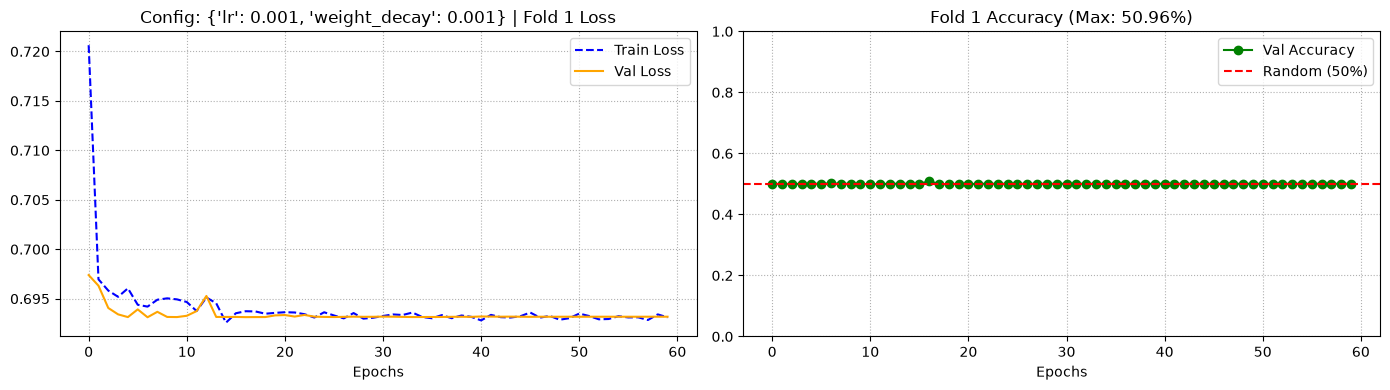


--- TRAINING SU FOLD 4/5 ---
Epoch 01/60: train_loss=0.72335, train_acc=49.56%, val_loss=0.69466, val_acc=49.49% | LR: 0.001000
Epoch 02/60: train_loss=0.69712, train_acc=51.13%, val_loss=0.69466, val_acc=49.49% | LR: 0.001000
Epoch 03/60: train_loss=0.69755, train_acc=49.18%, val_loss=0.69381, val_acc=49.49% | LR: 0.001000
Epoch 04/60: train_loss=0.69441, train_acc=49.84%, val_loss=0.69325, val_acc=50.51% | LR: 0.001000
Epoch 05/60: train_loss=0.69364, train_acc=50.73%, val_loss=0.69317, val_acc=51.76% | LR: 0.001000
Epoch 06/60: train_loss=0.69503, train_acc=51.59%, val_loss=0.69440, val_acc=49.49% | LR: 0.001000
Epoch 07/60: train_loss=0.69588, train_acc=49.61%, val_loss=0.69319, val_acc=50.51% | LR: 0.001000
Epoch 08/60: train_loss=0.69513, train_acc=49.76%, val_loss=0.69368, val_acc=50.51% | LR: 0.001000
Epoch 09/60: train_loss=0.69428, train_acc=50.36%, val_loss=0.69390, val_acc=50.51% | LR: 0.001000
Epoch 10/60: train_loss=0.69402, train_acc=50.36%, val_loss=0.69474, val_acc=49

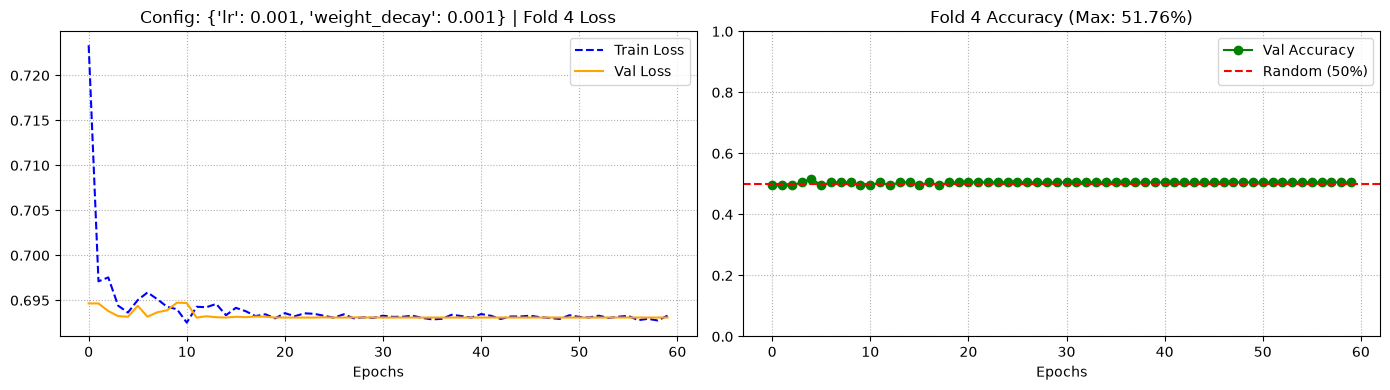

📊 Media accuracy (Fold 1 & 4) per {'lr': 0.001, 'weight_decay': 0.001}: 51.36%
--- COMBINATION 4/6 | Params: {'lr': 0.0005, 'weight_decay': 0.0001} ---

--- TRAINING SU FOLD 1/5 ---
Epoch 01/60: train_loss=0.70454, train_acc=50.13%, val_loss=0.69331, val_acc=49.94% | LR: 0.000500
Epoch 02/60: train_loss=0.69583, train_acc=50.67%, val_loss=0.69663, val_acc=50.06% | LR: 0.000500
Epoch 03/60: train_loss=0.69564, train_acc=50.59%, val_loss=0.69310, val_acc=51.86% | LR: 0.000500
Epoch 04/60: train_loss=0.69416, train_acc=49.84%, val_loss=0.69406, val_acc=50.06% | LR: 0.000500
Epoch 05/60: train_loss=0.69470, train_acc=49.78%, val_loss=0.69313, val_acc=49.94% | LR: 0.000500
Epoch 06/60: train_loss=0.69401, train_acc=49.58%, val_loss=0.69357, val_acc=50.06% | LR: 0.000500
Epoch 07/60: train_loss=0.69468, train_acc=49.70%, val_loss=0.69407, val_acc=49.94% | LR: 0.000500
Epoch 08/60: train_loss=0.69340, train_acc=50.79%, val_loss=0.69313, val_acc=50.06% | LR: 0.000500
Epoch 09/60: train_loss=0.

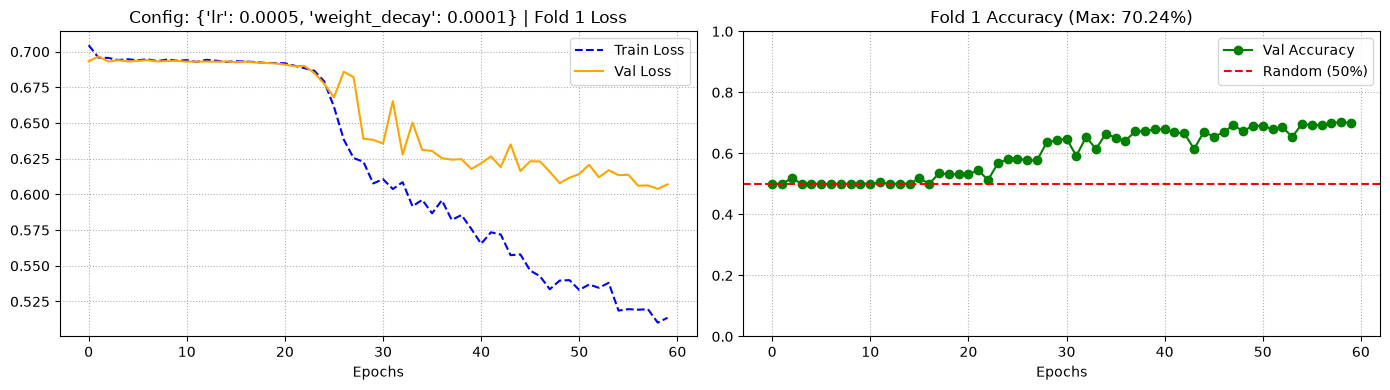


--- TRAINING SU FOLD 4/5 ---
Epoch 01/60: train_loss=0.71939, train_acc=48.09%, val_loss=0.69389, val_acc=50.51% | LR: 0.000500
Epoch 02/60: train_loss=0.69613, train_acc=49.50%, val_loss=0.69439, val_acc=49.49% | LR: 0.000500
Epoch 03/60: train_loss=0.69735, train_acc=48.95%, val_loss=0.69313, val_acc=50.51% | LR: 0.000500
Epoch 04/60: train_loss=0.69300, train_acc=50.44%, val_loss=0.69683, val_acc=49.49% | LR: 0.000500
Epoch 05/60: train_loss=0.69545, train_acc=49.84%, val_loss=0.69652, val_acc=50.51% | LR: 0.000500
Epoch 06/60: train_loss=0.69519, train_acc=48.87%, val_loss=0.69326, val_acc=50.51% | LR: 0.000500
Epoch 07/60: train_loss=0.69494, train_acc=49.87%, val_loss=0.69361, val_acc=50.51% | LR: 0.000250
Epoch 08/60: train_loss=0.69418, train_acc=50.79%, val_loss=0.69315, val_acc=50.51% | LR: 0.000250
Epoch 09/60: train_loss=0.69425, train_acc=49.24%, val_loss=0.69325, val_acc=49.49% | LR: 0.000250
Epoch 10/60: train_loss=0.69420, train_acc=49.30%, val_loss=0.69343, val_acc=49

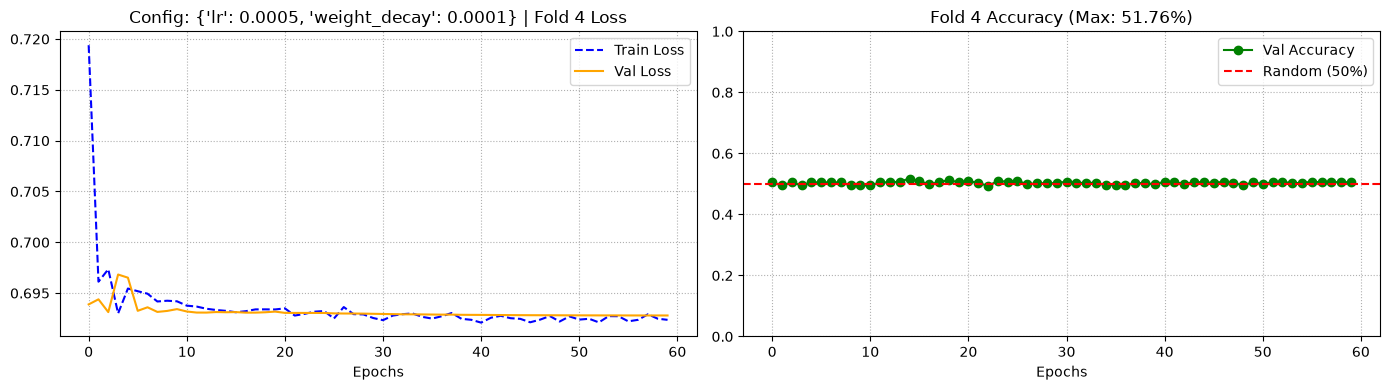

📊 Media accuracy (Fold 1 & 4) per {'lr': 0.0005, 'weight_decay': 0.0001}: 61.00%
--- COMBINATION 5/6 | Params: {'lr': 0.0005, 'weight_decay': 0.0005} ---

--- TRAINING SU FOLD 1/5 ---
Epoch 01/60: train_loss=0.70218, train_acc=51.11%, val_loss=0.69624, val_acc=49.94% | LR: 0.000500
Epoch 02/60: train_loss=0.69780, train_acc=49.04%, val_loss=0.69336, val_acc=50.06% | LR: 0.000500
Epoch 03/60: train_loss=0.69439, train_acc=49.70%, val_loss=0.69419, val_acc=50.06% | LR: 0.000500
Epoch 04/60: train_loss=0.69468, train_acc=50.36%, val_loss=0.69307, val_acc=49.94% | LR: 0.000500
Epoch 05/60: train_loss=0.69359, train_acc=51.11%, val_loss=0.69310, val_acc=49.94% | LR: 0.000500
Epoch 06/60: train_loss=0.69441, train_acc=50.13%, val_loss=0.69310, val_acc=50.06% | LR: 0.000500
Epoch 07/60: train_loss=0.69536, train_acc=48.49%, val_loss=0.69335, val_acc=50.06% | LR: 0.000500
Epoch 08/60: train_loss=0.69350, train_acc=50.67%, val_loss=0.69320, val_acc=50.06% | LR: 0.000250
Epoch 09/60: train_loss=

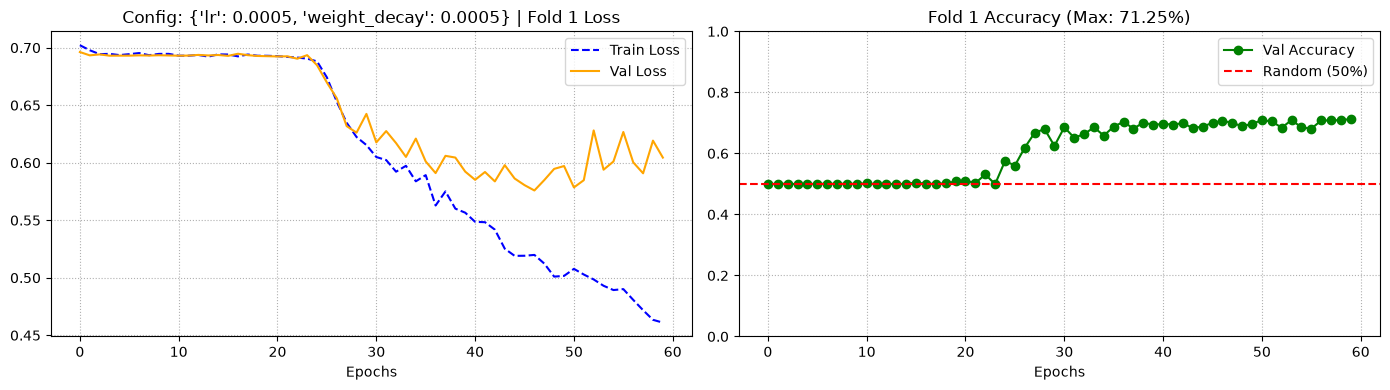


--- TRAINING SU FOLD 4/5 ---
Epoch 01/60: train_loss=0.70270, train_acc=50.64%, val_loss=0.69312, val_acc=51.99% | LR: 0.000500
Epoch 02/60: train_loss=0.69622, train_acc=50.33%, val_loss=0.69318, val_acc=51.76% | LR: 0.000500
Epoch 03/60: train_loss=0.69387, train_acc=50.87%, val_loss=0.69309, val_acc=50.51% | LR: 0.000500
Epoch 04/60: train_loss=0.69459, train_acc=50.07%, val_loss=0.69539, val_acc=49.49% | LR: 0.000500
Epoch 05/60: train_loss=0.69555, train_acc=51.28%, val_loss=0.69591, val_acc=50.51% | LR: 0.000500
Epoch 06/60: train_loss=0.69579, train_acc=49.76%, val_loss=0.69317, val_acc=49.49% | LR: 0.000500
Epoch 07/60: train_loss=0.69444, train_acc=50.47%, val_loss=0.69329, val_acc=50.51% | LR: 0.000250
Epoch 08/60: train_loss=0.69378, train_acc=49.84%, val_loss=0.69335, val_acc=50.51% | LR: 0.000250
Epoch 09/60: train_loss=0.69434, train_acc=50.56%, val_loss=0.69351, val_acc=49.49% | LR: 0.000250
Epoch 10/60: train_loss=0.69408, train_acc=48.61%, val_loss=0.69310, val_acc=49

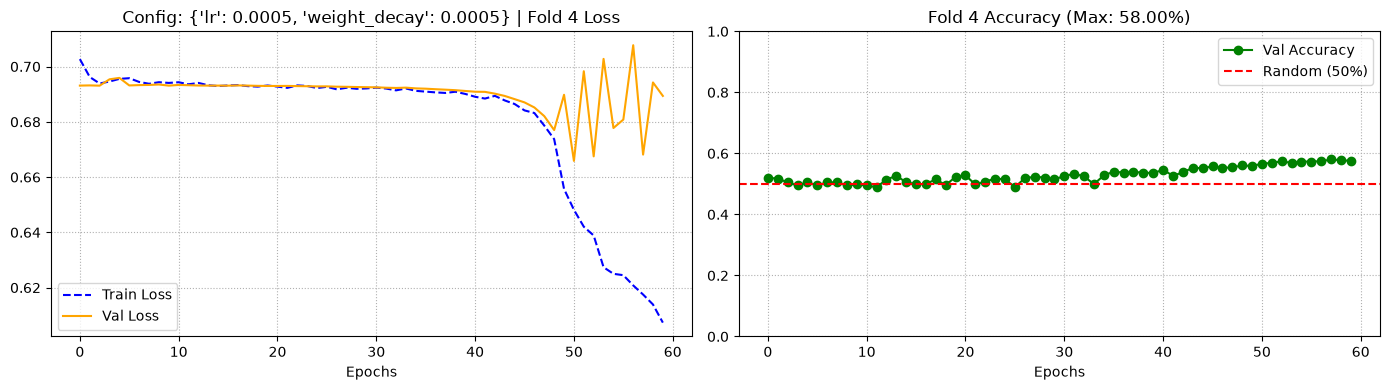

📊 Media accuracy (Fold 1 & 4) per {'lr': 0.0005, 'weight_decay': 0.0005}: 64.63%
--- COMBINATION 6/6 | Params: {'lr': 0.0005, 'weight_decay': 0.001} ---

--- TRAINING SU FOLD 1/5 ---
Epoch 01/60: train_loss=0.71043, train_acc=49.01%, val_loss=0.69294, val_acc=52.09% | LR: 0.000500
Epoch 02/60: train_loss=0.69545, train_acc=50.39%, val_loss=0.69393, val_acc=50.06% | LR: 0.000500
Epoch 03/60: train_loss=0.69480, train_acc=50.01%, val_loss=0.69737, val_acc=50.06% | LR: 0.000500
Epoch 04/60: train_loss=0.69616, train_acc=49.35%, val_loss=0.69483, val_acc=50.06% | LR: 0.000500
Epoch 05/60: train_loss=0.69467, train_acc=50.39%, val_loss=0.69523, val_acc=49.94% | LR: 0.000500
Epoch 06/60: train_loss=0.69488, train_acc=50.42%, val_loss=0.69314, val_acc=50.06% | LR: 0.000500
Epoch 07/60: train_loss=0.69439, train_acc=50.82%, val_loss=0.69301, val_acc=50.51% | LR: 0.000250
Epoch 08/60: train_loss=0.69365, train_acc=50.62%, val_loss=0.69581, val_acc=50.06% | LR: 0.000250
Epoch 09/60: train_loss=0

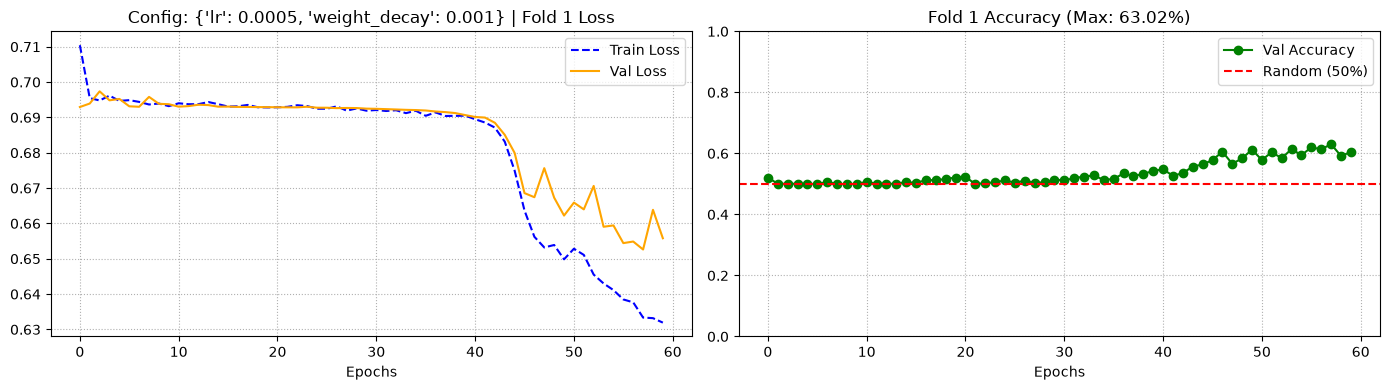


--- TRAINING SU FOLD 4/5 ---
Epoch 01/60: train_loss=0.71712, train_acc=49.30%, val_loss=0.70114, val_acc=49.49% | LR: 0.000500
Epoch 02/60: train_loss=0.70113, train_acc=48.61%, val_loss=0.69603, val_acc=50.51% | LR: 0.000500
Epoch 03/60: train_loss=0.69710, train_acc=47.64%, val_loss=0.69310, val_acc=50.51% | LR: 0.000500
Epoch 04/60: train_loss=0.69427, train_acc=49.87%, val_loss=0.69407, val_acc=49.49% | LR: 0.000500
Epoch 05/60: train_loss=0.69477, train_acc=49.44%, val_loss=0.69317, val_acc=49.49% | LR: 0.000500
Epoch 06/60: train_loss=0.69475, train_acc=49.04%, val_loss=0.69378, val_acc=49.49% | LR: 0.000500
Epoch 07/60: train_loss=0.69578, train_acc=50.50%, val_loss=0.69321, val_acc=50.51% | LR: 0.000500
Epoch 08/60: train_loss=0.69392, train_acc=48.15%, val_loss=0.69359, val_acc=50.51% | LR: 0.000250
Epoch 09/60: train_loss=0.69416, train_acc=50.62%, val_loss=0.69319, val_acc=50.51% | LR: 0.000250
Epoch 10/60: train_loss=0.69350, train_acc=50.21%, val_loss=0.69312, val_acc=50

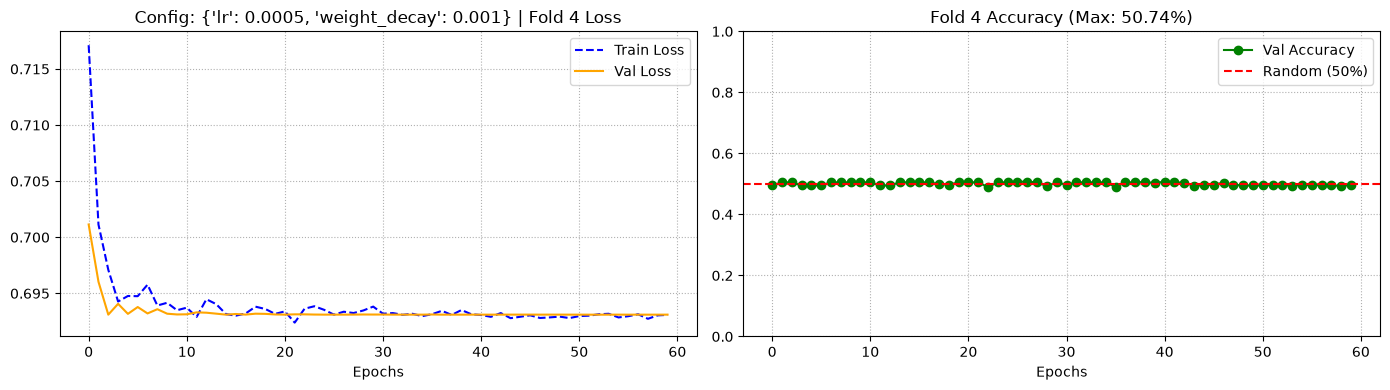

📊 Media accuracy (Fold 1 & 4) per {'lr': 0.0005, 'weight_decay': 0.001}: 56.88%
 COMPLETE SCREENING SUMMARY (ON FOLDS 1 & 4):
Parameters {'lr': 0.001, 'weight_decay': 0.0001} ➔ Mean Val Accuracy: 70.35%
Parameters {'lr': 0.001, 'weight_decay': 0.0005} ➔ Mean Val Accuracy: 65.06%
Parameters {'lr': 0.001, 'weight_decay': 0.001} ➔ Mean Val Accuracy: 51.36%
Parameters {'lr': 0.0005, 'weight_decay': 0.0001} ➔ Mean Val Accuracy: 61.00%
Parameters {'lr': 0.0005, 'weight_decay': 0.0005} ➔ Mean Val Accuracy: 64.63%
Parameters {'lr': 0.0005, 'weight_decay': 0.001} ➔ Mean Val Accuracy: 56.88%


In [7]:
import itertools
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import ReduceLROnPlateau

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


param_grid = {
    'lr': [1e-3, 5e-4],
    'weight_decay': [1e-4, 5e-4, 1e-3]
}

keys = param_grid.keys()
values = param_grid.values()
param_combinations = [dict(zip(keys, combination)) for combination in itertools.product(*values)]

BATCH_SIZE = 64       
EPOCHS = 60           
ALPHA_NOISE = 0.01     
EPSILON = 1e-8


gkf = GroupKFold(n_splits=5)

all_splits = list(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation))

target_fold_indices = [0, 3]

grid_results = {}
best_global_score = 0.0
best_params = None

# 2. Ciclo sulle combinazioni di iperparametri
for i, params in enumerate(param_combinations, 1):
    print(f"==========================================")
    print(f"--- COMBINATION {i}/{len(param_combinations)} | Params: {params} ---")
    print(f"==========================================")
    
    fold_accuracies = []
    
    for fold_idx in target_fold_indices:
        print(f"\n--- TRAINING SU FOLD {fold_idx + 1}/5 ---")
        
        train_idx, val_idx = all_splits[fold_idx]
        
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

        X_train_norm = (X_train_raw - train_mean) / (train_std + EPSILON)
        noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise

        X_val_final = (X_val_raw - train_mean) / (train_std + EPSILON)

        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)

        train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

        model = F_CTrans_modified(num_channels=64, d_model=128, nhead=8, d_ff=512, dropout=0.4, num_layers=2, num_classes=2).to(device)
        
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=params['lr'], betas=(0.9, 0.95), weight_decay=params['weight_decay'])
        scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5, min_lr=1e-6)
        
        trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)
        
        best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader, epochs=EPOCHS, scheduler=scheduler)

        print(f" Fold {fold_idx + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")
        fold_accuracies.append(best_val_acc)

        plt.figure(figsize=(14, 4))
        plt.subplot(1, 2, 1)
        plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
        plt.plot(val_losses, linestyle='-', color='orange', label='Val Loss')
        plt.title(f'Config: {params} | Fold {fold_idx + 1} Loss')
        plt.xlabel('Epochs')
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, marker='o', color='green', label='Val Accuracy')
        plt.axhline(y=0.5, color='red', linestyle='--', label='Random (50%)')
        plt.title(f'Fold {fold_idx + 1} Accuracy (Max: {max(val_accuracies)*100:.2f}%)')
        plt.xlabel('Epochs')
        plt.ylim(0.0, 1.0)
        plt.legend()
        plt.grid(True, linestyle=':')
        plt.tight_layout()
        plt.show()

    mean_score = np.mean(fold_accuracies)
    grid_results[str(params)] = mean_score
    print(f"📊 Media accuracy (Fold 1 & 4) per {params}: {mean_score*100:.2f}%")

    if mean_score > best_global_score:
        best_global_score = mean_score
        best_params = params

print(f" COMPLETE SCREENING SUMMARY (ON FOLDS 1 & 4):")
for config, acc in grid_results.items():
    print(f"Parameters {config} ➔ Mean Val Accuracy: {acc*100:.2f}%")


## 5. Training on Full Train Set & Checkpoint Saving

After evaluating the grid search combinations across the selected folds, I selected the optimal hyperparameters. Rather than choosing the configuration that strictly maximized validation accuracy, I opted for a balanced trade-off between strong validation accuracy and low validation loss to ensure better generalization.

**Chosen Hyperparameters:**
- **Learning Rate (`lr`):** [0.001]
- **Weight Decay (`weight_decay`):** [0.0001]


 Detected device: GPU NVIDIA (CUDA)
START TRAINING AND VALIDAZIONE - FOLD 1/5 
Epoch 01/50: train_loss=0.72125, train_acc=50.45%, val_loss=0.69627, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69651, train_acc=51.51%, val_loss=0.69595, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69695, train_acc=49.81%, val_loss=0.69495, val_acc=49.94% | LR: 0.001000
Epoch 04/50: train_loss=0.69557, train_acc=50.50%, val_loss=0.70132, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69557, train_acc=50.65%, val_loss=0.69420, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69649, train_acc=48.23%, val_loss=0.69385, val_acc=49.94% | LR: 0.001000
Epoch 07/50: train_loss=0.69439, train_acc=49.38%, val_loss=0.69312, val_acc=49.94% | LR: 0.001000
Epoch 08/50: train_loss=0.69396, train_acc=50.76%, val_loss=0.69339, val_acc=49.94% | LR: 0.001000
Epoch 09/50: train_loss=0.69593, train_acc=48.81%, val_loss=0.69325, val_acc=49.94% | LR: 0.001000
Epoch 10/50: train_loss=0.6942

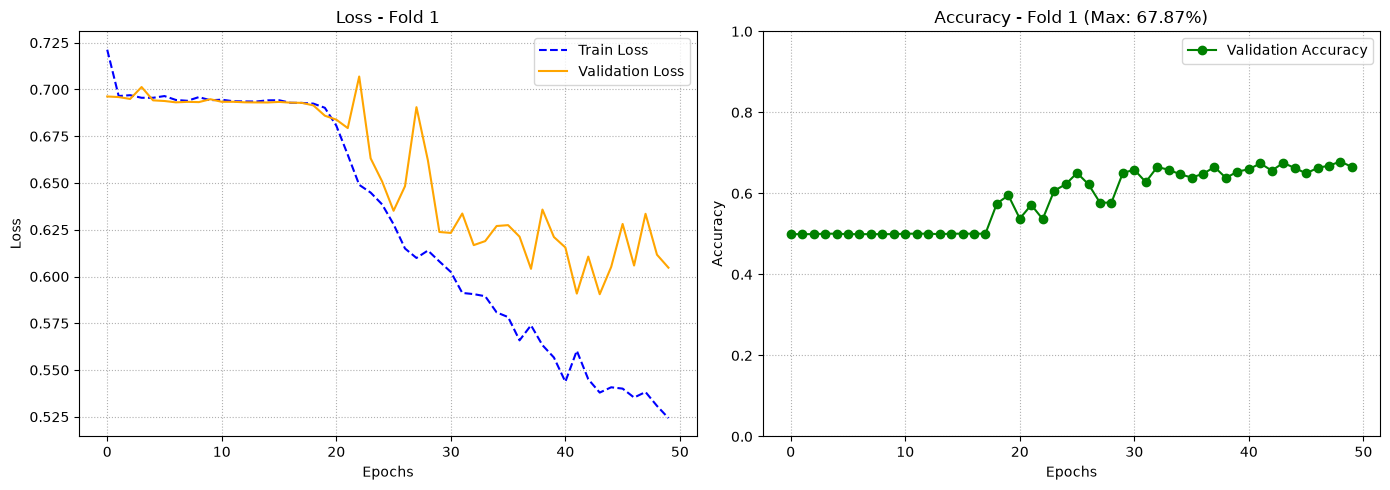

START TRAINING AND VALIDAZIONE - FOLD 2/5 
Epoch 01/50: train_loss=0.72477, train_acc=51.05%, val_loss=0.69325, val_acc=49.88% | LR: 0.001000
Epoch 02/50: train_loss=0.69707, train_acc=50.77%, val_loss=0.69456, val_acc=50.12% | LR: 0.001000
Epoch 03/50: train_loss=0.69528, train_acc=50.26%, val_loss=0.69384, val_acc=50.12% | LR: 0.001000
Epoch 04/50: train_loss=0.69519, train_acc=50.83%, val_loss=0.70576, val_acc=50.12% | LR: 0.001000
Epoch 05/50: train_loss=0.69447, train_acc=50.60%, val_loss=0.69619, val_acc=49.88% | LR: 0.001000
Epoch 06/50: train_loss=0.69352, train_acc=50.83%, val_loss=0.69313, val_acc=52.33% | LR: 0.001000
Epoch 07/50: train_loss=0.69623, train_acc=48.63%, val_loss=0.70103, val_acc=50.12% | LR: 0.001000
Epoch 08/50: train_loss=0.69444, train_acc=49.94%, val_loss=0.69323, val_acc=49.88% | LR: 0.001000
Epoch 09/50: train_loss=0.69394, train_acc=50.23%, val_loss=0.69406, val_acc=50.12% | LR: 0.001000
Epoch 10/50: train_loss=0.69469, train_acc=49.06%, val_loss=0.6933

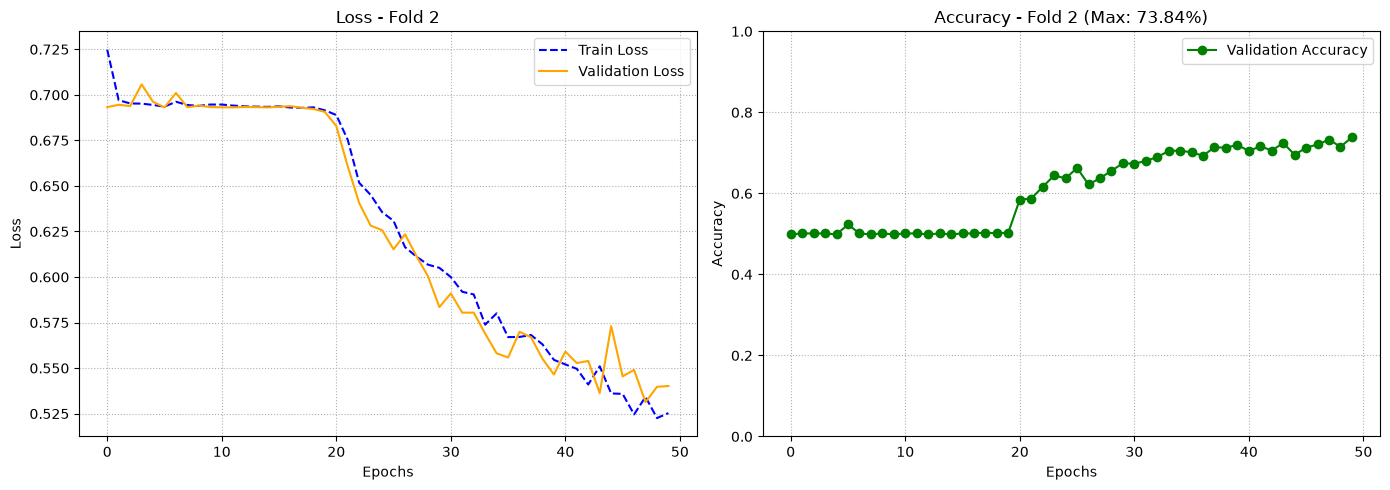

START TRAINING AND VALIDAZIONE - FOLD 3/5 
Epoch 01/50: train_loss=0.71428, train_acc=51.47%, val_loss=0.70370, val_acc=49.48% | LR: 0.001000
Epoch 02/50: train_loss=0.70077, train_acc=48.48%, val_loss=0.70082, val_acc=50.52% | LR: 0.001000
Epoch 03/50: train_loss=0.69775, train_acc=49.53%, val_loss=0.69312, val_acc=50.52% | LR: 0.001000
Epoch 04/50: train_loss=0.69523, train_acc=50.44%, val_loss=0.69925, val_acc=50.52% | LR: 0.001000
Epoch 05/50: train_loss=0.69704, train_acc=50.41%, val_loss=0.69556, val_acc=49.48% | LR: 0.001000
Epoch 06/50: train_loss=0.69257, train_acc=52.04%, val_loss=0.69468, val_acc=50.52% | LR: 0.001000
Epoch 07/50: train_loss=0.69409, train_acc=50.21%, val_loss=0.69412, val_acc=50.52% | LR: 0.001000
Epoch 08/50: train_loss=0.69544, train_acc=49.27%, val_loss=0.69448, val_acc=49.48% | LR: 0.000500
Epoch 09/50: train_loss=0.69551, train_acc=47.99%, val_loss=0.69330, val_acc=49.48% | LR: 0.000500
Epoch 10/50: train_loss=0.69337, train_acc=50.73%, val_loss=0.6930

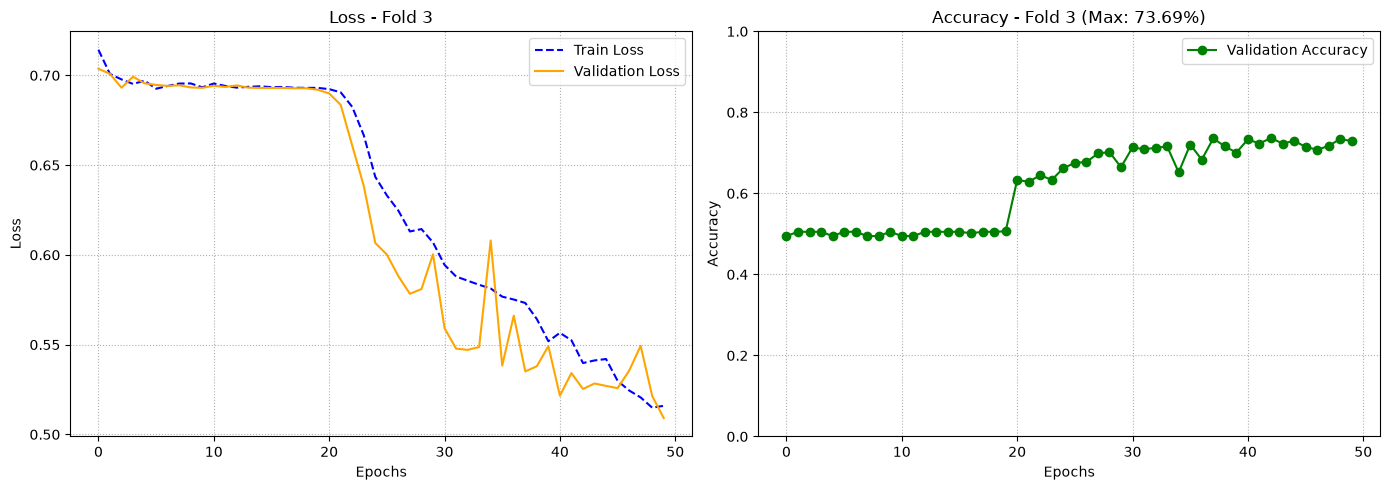

START TRAINING AND VALIDAZIONE - FOLD 4/5 
Epoch 01/50: train_loss=0.71388, train_acc=49.30%, val_loss=0.69468, val_acc=50.51% | LR: 0.001000
Epoch 02/50: train_loss=0.69830, train_acc=48.61%, val_loss=0.69317, val_acc=49.49% | LR: 0.001000
Epoch 03/50: train_loss=0.69462, train_acc=50.27%, val_loss=0.69311, val_acc=50.51% | LR: 0.001000
Epoch 04/50: train_loss=0.69477, train_acc=51.65%, val_loss=0.69312, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69524, train_acc=49.73%, val_loss=0.69806, val_acc=49.49% | LR: 0.001000
Epoch 06/50: train_loss=0.69498, train_acc=51.45%, val_loss=0.69353, val_acc=49.49% | LR: 0.001000
Epoch 07/50: train_loss=0.69345, train_acc=51.36%, val_loss=0.69308, val_acc=50.51% | LR: 0.000500
Epoch 08/50: train_loss=0.69503, train_acc=50.53%, val_loss=0.69571, val_acc=49.49% | LR: 0.000500
Epoch 09/50: train_loss=0.69736, train_acc=47.66%, val_loss=0.69309, val_acc=50.51% | LR: 0.000500
Epoch 10/50: train_loss=0.69458, train_acc=49.81%, val_loss=0.6930

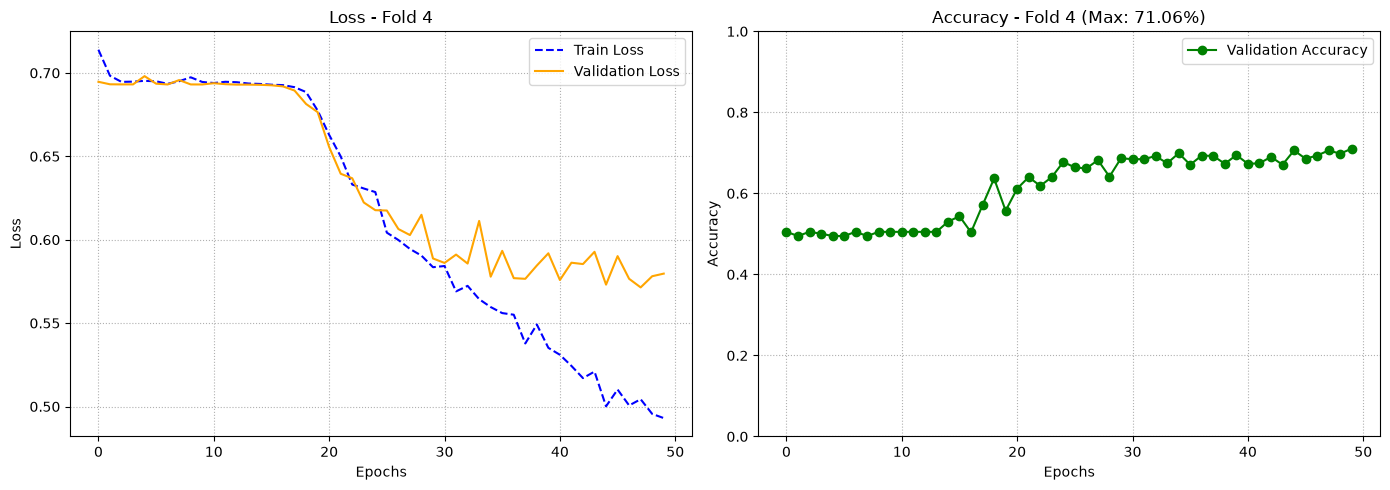

START TRAINING AND VALIDAZIONE - FOLD 5/5 
Epoch 01/50: train_loss=0.70931, train_acc=49.96%, val_loss=0.69292, val_acc=51.08% | LR: 0.001000
Epoch 02/50: train_loss=0.69541, train_acc=50.10%, val_loss=0.69822, val_acc=48.92% | LR: 0.001000
Epoch 03/50: train_loss=0.69623, train_acc=50.59%, val_loss=0.69395, val_acc=48.92% | LR: 0.001000
Epoch 04/50: train_loss=0.69487, train_acc=50.01%, val_loss=0.69493, val_acc=48.92% | LR: 0.001000
Epoch 05/50: train_loss=0.69825, train_acc=48.64%, val_loss=0.69312, val_acc=51.08% | LR: 0.001000
Epoch 06/50: train_loss=0.69543, train_acc=50.36%, val_loss=0.69292, val_acc=51.08% | LR: 0.001000
Epoch 07/50: train_loss=0.69500, train_acc=49.81%, val_loss=0.69290, val_acc=51.08% | LR: 0.000500
Epoch 08/50: train_loss=0.69435, train_acc=50.36%, val_loss=0.69483, val_acc=48.92% | LR: 0.000500
Epoch 09/50: train_loss=0.69612, train_acc=48.61%, val_loss=0.69301, val_acc=51.08% | LR: 0.000500
Epoch 10/50: train_loss=0.69501, train_acc=48.52%, val_loss=0.6935

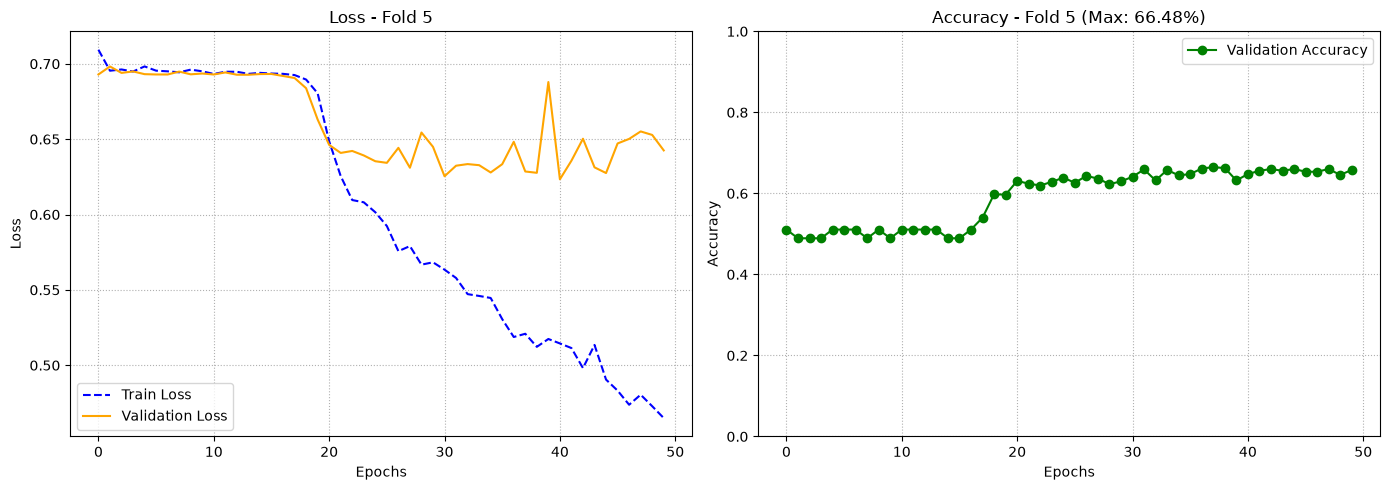

 TRAINING COMPLETED ON ALL FOLDS!
 Mean cross-validation accuracy: 70.59% (± 2.99%)
 All fold weights have been saved in the folder: '/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/roadtrip/saved_models'


In [10]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from pathlib import Path  

if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50          
LR = 0.001       
WEIGHT_DECAY = 0.0001 
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

models_dir = Path("saved_models")
models_dir.mkdir(parents=True, exist_ok=True)

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)

    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

    X_train_norm = (X_train_raw - train_mean) / (train_std + EPSILON)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + EPSILON)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modified(num_channels = 64, d_model = 128, nhead = 8, d_ff = 512, dropout = 0.4, num_layers = 2, num_classes = 2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5, min_lr=1e-6)
  
    trainer = EEGTrainer(model=model, criterion=criterion, optimizer=optimizer, device=device)

    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader, epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

   
    checkpoint = {
        'fold': fold + 1,
        'model_state_dict': model.state_dict(),
        'best_val_acc': best_val_acc,
        'hyperparameters': {
            'num_channels': 64,
            'd_model': 128,
            'nhead': 8,
            'd_ff': 512,
            'dropout': 0.4,
            'num_layers': 2,
            'num_classes': 2,
            'lr': LR,
            'weight_decay': WEIGHT_DECAY
        }
    }

    fold_model_path = models_dir / f"f_ctrans_modified_besthyp_fold_{fold + 1}.pth"
    torch.save(checkpoint, fold_model_path)
    print(f"Fold {fold + 1} weights saved to: {fold_model_path}")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()
        
        best_global_path = models_dir / "best_global_f_ctrans_modified.pth"
        torch.save(checkpoint, best_global_path)
        print(f" New global record! Saved the absolute best model to: {best_global_path}")

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    
print(f" TRAINING COMPLETED ON ALL FOLDS!")
print(f" Mean cross-validation accuracy: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")
print(f" All fold weights have been saved in the folder: '{models_dir.resolve()}'")

 Re-running to save training mean and std, needed later to normalize the test set

In [12]:
import torch
import numpy as np
from sklearn.model_selection import GroupKFold
from pathlib import Path

models_dir = Path("saved_models")
gkf = GroupKFold(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    X_train_raw = X_training_validation_raw[train_idx]
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
  
    model_path = models_dir / f"f_ctrans_modified_besthyp_fold_{fold + 1}.pth"
    
    if model_path.exists():
        checkpoint = torch.load(model_path, map_location='cpu')
        
        checkpoint['train_mean'] = train_mean
        checkpoint['train_std'] = train_std
        
        torch.save(checkpoint, model_path)
        print(f"Fold {fold + 1}: train_mean and train_std saved in {model_path.name}!")
    else:
        print(f"Warning: File {model_path.name} was not found.")

print(" Done ")

Fold 1: train_mean and train_std saved in f_ctrans_modified_besthyp_fold_1.pth!
Fold 2: train_mean and train_std saved in f_ctrans_modified_besthyp_fold_2.pth!
Fold 3: train_mean and train_std saved in f_ctrans_modified_besthyp_fold_3.pth!
Fold 4: train_mean and train_std saved in f_ctrans_modified_besthyp_fold_4.pth!
Fold 5: train_mean and train_std saved in f_ctrans_modified_besthyp_fold_5.pth!
 Done 


## 6. Final Evaluation on Test Set

In this final section, I load the best-performing model weights obtained from our training pipeline.
To evaluate the generalization performance of yhe model on the unseen **Test Set**, I employ an **Ensemble Strategy**:
1. **Model Loading:** We load the saved weights from each of the 5 cross-validation folds.
2. **Data Normalization:** The test data (`X_test_raw`) is normalized using the respective training mean and standard deviation (`train_mean`, `train_std`) saved during each fold's training phase.
3. **Probability Averaging:** For each sample, the output probabilities from all 5 fold models are averaged (`ensemble_probs`) to make the final prediction via `argmax`.


In [12]:
import torch
import torch.nn.functional as F
import numpy as np
from torch.utils.data import DataLoader
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")



models_dir = Path("saved_models")
BATCH_SIZE = 64
EPSILON = 1e-8

all_fold_probabilities = []

for fold in range(1, 6):
    model_path = models_dir / f"f_ctrans_modified_besthyp_fold_{fold}.pth"
    print(f" [Fold {fold}/5] Processing with model: {model_path.name}")

    
    checkpoint = torch.load(model_path, map_location='cpu',weights_only=False)
    
    model_state_dict = checkpoint['model_state_dict']
    train_mean = checkpoint['train_mean']
    train_std = checkpoint['train_std']
    hp = checkpoint['hyperparameters']
    
    model = F_CTrans_modified( num_channels=hp['num_channels'],d_model=hp['d_model'], nhead=hp['nhead'], d_ff=hp['d_ff'], dropout=hp['dropout'], num_layers=hp['num_layers'], num_classes=hp['num_classes']).to(device)
    
    model.load_state_dict(model_state_dict)
    model.eval()
    
    X_test_norm = (X_test_raw - train_mean) / (train_std + EPSILON)
    
    test_dataset = EEGDataset(X_test_norm, y_test)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    fold_probs = []
    with torch.no_grad(): 
        for x_batch, _ in test_loader:
            x_batch = x_batch.to(device)
            
            outputs = model(x_batch) 
            
            if isinstance(outputs, tuple):
                outputs = outputs[0]
                
            probs = F.softmax(outputs, dim=1)
            fold_probs.append(probs.cpu().numpy())
            
    fold_probs = np.concatenate(fold_probs, axis=0)
    all_fold_probabilities.append(fold_probs)
    print(f" [Fold {fold}] Completed.")


print(" Calculating Ensemble (Averaging probabilities across the 5 models)")
# Average along the folds axis (axis 0)
ensemble_probs = np.mean(all_fold_probabilities, axis=0)

# Select the final class with the highest average probability (Argmax)
y_pred_ensemble = np.argmax(ensemble_probs, axis=1)

final_accuracy = accuracy_score(y_test, y_pred_ensemble)


print(f" FINAL TEST SET RESULT (5-FOLD ENSEMBLE):")
print(f"Test Accuracy: {final_accuracy * 100:.2f}%")

output_path = models_dir / "test_predictions.npz"
np.savez(output_path, y_true=y_test, y_pred=y_pred_ensemble, ensemble_probs=ensemble_probs)
print(f" Results  saved to: {output_path}")


 Detected device: GPU NVIDIA (CUDA)
 [Fold 1/5] Processing with model: f_ctrans_modified_besthyp_fold_1.pth


/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/venv/lib/python3.12/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv2d(


 [Fold 1] Completed.
 [Fold 2/5] Processing with model: f_ctrans_modified_besthyp_fold_2.pth
 [Fold 2] Completed.
 [Fold 3/5] Processing with model: f_ctrans_modified_besthyp_fold_3.pth
 [Fold 3] Completed.
 [Fold 4/5] Processing with model: f_ctrans_modified_besthyp_fold_4.pth
 [Fold 4] Completed.
 [Fold 5/5] Processing with model: f_ctrans_modified_besthyp_fold_5.pth
 [Fold 5] Completed.
 Calculating Ensemble (Averaging probabilities across the 5 models)
 FINAL TEST SET RESULT (5-FOLD ENSEMBLE):
Test Accuracy: 67.88%
 Results  saved to: saved_models/test_predictions.npz
